# 03 : cible corrigée, probabilités calibrées, SHAP par commune

Trois corrections par rapport aux notebooks 01 et 02 :
1. **Cible** : compter les arrêtés distincts (pas les lignes), rattacher les anciens codes INSEE (communes fusionnées) à la commune actuelle, et garder les communes **sans aucun arrêté** (classe 0).
2. **Calibration** : `scale_pos_weight` gonfle les probabilités (moyenne 0,43 pour une prévalence de 0,235). On compare avec un modèle sans pondération.
3. **Explicabilité** : valeurs SHAP calculées hors échantillon (même découpage que les prédictions), pour les afficher commune par commune dans l'app.

In [1]:
import glob
import time
import warnings

import geopandas as gpd
import numpy as np
import pandas as pd
import requests
from google.cloud import bigquery

warnings.filterwarnings("ignore", message="BigQuery Storage module not found")
client = bigquery.Client(project="wagon-bootcamp-501621")

# Communes actuelles (France entière) : sert à repérer les anciens codes
r = requests.get("https://geo.api.gouv.fr/communes",
                 params={"fields": "code,nom,codeDepartement,centre", "format": "json"})
toutes = pd.DataFrame(r.json())
toutes["lon"] = toutes["centre"].apply(lambda c: c["coordinates"][0])
toutes["lat"] = toutes["centre"].apply(lambda c: c["coordinates"][1])
toutes = toutes.drop(columns="centre")
codes_actuels = set(toutes["code"])

# France métropolitaine : on filtre sur le code commune (les COM du Pacifique n'ont pas de codeDepartement)
communes = toutes[~toutes["code"].str[:2].isin(["97", "98"])].reset_index(drop=True)
print("Communes actuelles :", len(toutes), "| métropole :", len(communes))

Communes actuelles : 34969 | métropole : 34746


In [2]:
# Une ligne par (commune, arrêté, péril) inondation
arretes = client.query("""
    SELECT code_commune, id_gaspar
    FROM `wagon-bootcamp-501621.staging.catnat_staging`
    WHERE lib_risque_jo IN ('inondations et/ou coulees de boue',
                            'inondations remontee nappe')
""").to_dataframe()

doublons = arretes.duplicated(["code_commune", "id_gaspar"]).sum()
print("Lignes :", len(arretes), "| doublons (même commune, même arrêté) :", doublons)

anciens = set(arretes["code_commune"]) - codes_actuels
print("Codes GASPAR qui ne sont plus des communes actuelles :", len(anciens))

Lignes : 140787 | doublons (même commune, même arrêté) : 3347
Codes GASPAR qui ne sont plus des communes actuelles : 102


In [3]:
# Historique des fusions de communes (INSEE, Code officiel géographique 2026)
mvt = pd.read_csv("https://www.insee.fr/fr/statistiques/fichier/8740222/v_mvt_commune_2026.csv",
                  dtype=str)
mvt = mvt[(mvt["TYPECOM_AP"] == "COM") & (mvt["COM_AV"] != mvt["COM_AP"])]
suivant = mvt.sort_values("DATE_EFF").groupby("COM_AV")["COM_AP"].last().to_dict()

def code_actuel(code):
    """Suit les fusions successives jusqu'à une commune qui existe aujourd'hui."""
    vus = set()
    while code not in codes_actuels and code in suivant and code not in vus:
        vus.add(code)
        code = suivant[code]
    return code

arretes["code_actuel"] = arretes["code_commune"].map(code_actuel)
print("Anciens codes non rattachés :", (~arretes["code_actuel"].isin(codes_actuels)).sum())
print(arretes.loc[arretes["code_commune"] != arretes["code_actuel"],
                  ["code_commune", "code_actuel"]].drop_duplicates().head())

Anciens codes non rattachés : 0
     code_commune code_actuel
348         70557       70152
410         70530       70180
431         70264       70180
1302        46217       46172
1449        42252       42084


In [4]:
# Nombre d'arrêtés distincts par commune actuelle (un arrêté commun à deux anciennes communes compte une fois)
nb = (arretes.drop_duplicates(["code_actuel", "id_gaspar"])
             .groupby("code_actuel").size().rename("nb_arretes_inond"))

# Toutes les communes de métropole, y compris celles sans aucun arrêté
df = communes.rename(columns={"code": "code_commune"}).merge(
    nb, left_on="code_commune", right_index=True, how="left")
df["nb_arretes_inond"] = df["nb_arretes_inond"].fillna(0).astype(int)
df["risque_fort"] = (df["nb_arretes_inond"] >= 6).astype(int)

print("Communes sans aucun arrêté :", (df["nb_arretes_inond"] == 0).sum())
print(df["nb_arretes_inond"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(2))
print(df["risque_fort"].value_counts(normalize=True).round(3))

# Comparaison avec l'ancienne cible
v1 = pd.read_parquet("../data/communes_cible_swi_relief.parquet")
comp = v1[["code_commune", "nb_arretes_inond"]].merge(
    df[["code_commune", "nb_arretes_inond"]], on="code_commune", suffixes=("_v1", "_v3"))
print("Communes dont le nombre d'arrêtés change :",
      (comp["nb_arretes_inond_v1"] != comp["nb_arretes_inond_v3"]).sum())

Communes sans aucun arrêté : 388
count    34746.00
mean         3.93
std          2.63
min          0.00
25%          2.00
50%          3.00
75%          5.00
90%          7.00
max         32.00
Name: nb_arretes_inond, dtype: float64
risque_fort
0    0.78
1    0.22
Name: proportion, dtype: float64
Communes dont le nombre d'arrêtés change : 2904


## Cible corrigée
- 3 347 doublons retirés : le même arrêté pouvait apparaître deux fois pour une commune
- 102 anciens codes rattachés à leur commune actuelle grâce à l'historique INSEE
- 388 communes sans aucun arrêté inondation ajoutées (classe 0)
- La distribution reste la même (médiane 3, 75ᵉ percentile 5) : on garde le seuil `risque_fort` = 6 arrêtés ou plus
- Limite : une commune nouvelle cumule les arrêtés de ses anciennes communes, et une grande commune a mécaniquement plus de chances d'en avoir

In [5]:
# SWI : même méthode que le notebook 01 (plus proche point de grille, 10 km max)
swi_points = client.query("""
    SELECT
        NUMERO,
        ANY_VALUE(LAMBX) AS lambx,
        ANY_VALUE(LAMBY) AS lamby,
        AVG(SWI_UNIF_MENS)                               AS swi_moyen,
        MAX(SWI_UNIF_MENS)                               AS swi_max,
        APPROX_QUANTILES(SWI_UNIF_MENS, 100)[OFFSET(90)] AS swi_p90,
        AVG(IF(SWI_UNIF_MENS >= 1, 1, 0))                AS part_mois_sature
    FROM `wagon-bootcamp-501621.staging.donnees_50_ans_swi_staging`
    WHERE SUBSTR(CAST(DATE AS STRING), 1, 4) >= '1982'
    GROUP BY NUMERO
""").to_dataframe()

pts = gpd.GeoDataFrame(swi_points, crs="EPSG:2154",
                       geometry=gpd.points_from_xy(swi_points["lambx"], swi_points["lamby"]))
com = gpd.GeoDataFrame(df[["code_commune"]], crs="EPSG:4326",
                       geometry=gpd.points_from_xy(df["lon"], df["lat"])).to_crs(2154)

cols_swi = ["swi_moyen", "swi_max", "swi_p90", "part_mois_sature"]
j = gpd.sjoin_nearest(com, pts[cols_swi + ["geometry"]], how="left", max_distance=10_000)
df = df.merge(j.drop_duplicates("code_commune")[["code_commune"] + cols_swi],
              on="code_commune", how="left")
print("Communes sans SWI :", df["swi_moyen"].isna().sum())

Communes sans SWI : 2


In [6]:
def altitudes_ign(lats, lons, essais=5):
    """Altitude IGN (RGE ALTI) pour une liste de points, avec plusieurs essais."""
    for tentative in range(essais):
        try:
            r = requests.get(
                "https://data.geopf.fr/altimetrie/1.0/calcul/alti/rest/elevation.json",
                params={"lon": "|".join(f"{x:.5f}" for x in lons),
                        "lat": "|".join(f"{x:.5f}" for x in lats),
                        "resource": "ign_rge_alti_wld",
                        "zonly": "true"},
                timeout=60,
            )
            r.raise_for_status()
            return r.json()["elevations"]
        except requests.exceptions.RequestException as e:
            print(f"Essai {tentative + 1} raté : {type(e).__name__}")
            time.sleep(10)
    raise RuntimeError("API IGN injoignable")

# Réutiliser les altitudes du notebook 01, n'interroger l'IGN que pour les communes manquantes
pts_alt = pd.read_parquet("../data/altitudes_points.parquet")
fichier_compl = "../data/altitudes_points_complement.parquet"
manquantes = df[~df["code_commune"].isin(pts_alt["code_commune"])]
print("Communes sans altitude :", len(manquantes))

try:
    compl = pd.read_parquet(fichier_compl)
except FileNotFoundError:
    g = gpd.GeoDataFrame(manquantes[["code_commune"]], crs="EPSG:4326",
                         geometry=gpd.points_from_xy(manquantes["lon"], manquantes["lat"])).to_crs(2154)
    decalages = {"c": (0, 0), "n": (0, 1000), "s": (0, -1000), "e": (1000, 0), "o": (-1000, 0)}
    morceaux = []
    for pos, (dx, dy) in decalages.items():
        p = g.geometry.translate(dx, dy).to_crs(4326)
        morceaux.append(pd.DataFrame({"code_commune": manquantes["code_commune"].values,
                                      "pos": pos, "lon": p.x.values, "lat": p.y.values}))
    compl = pd.concat(morceaux, ignore_index=True)
    elev = []
    for i in range(0, len(compl), 200):
        lot = compl.iloc[i:i + 200]
        elev += altitudes_ign(lot["lat"], lot["lon"])
        time.sleep(0.3)
    compl["alt"] = elev
    compl.to_parquet(fichier_compl, index=False)

pts_alt = pd.concat([pts_alt, compl], ignore_index=True)
pts_alt.loc[pts_alt["alt"] < -10, "alt"] = np.nan   # mer, plans d'eau, -99999

alt = pts_alt.pivot(index="code_commune", columns="pos", values="alt")
voisins = alt[["n", "s", "e", "o"]]
relief = pd.DataFrame({
    "altitude": alt["c"],
    "denivele_local": alt.max(axis=1) - alt.min(axis=1),
    "pente_max_pct": voisins.sub(alt["c"], axis=0).abs().max(axis=1) / 1000 * 100,
    "position_relative": alt["c"] - voisins.mean(axis=1),
}).reset_index()
df = df.merge(relief, on="code_commune", how="left")
print("Communes sans altitude au centre :", df["altitude"].isna().sum())

Communes sans altitude : 393


Communes sans altitude au centre : 36


In [7]:
# Pluies extrêmes : fichiers annuels calculés dans le notebook 02
annuel = pd.concat(pd.read_parquet(f) for f in glob.glob("../data/pluies_annuelles/*.parquet"))
pluie_pts = annuel.groupby(["LAMBX", "LAMBY"]).agg(
    pluie_max_jour_moy=("pluie_max_jour", "mean"),
    pluie_max_jour_abs=("pluie_max_jour", "max"),
    nb_jours_50mm_an=("nb_jours_50mm", "mean"),
    cumul_annuel_moy=("cumul_annuel", "mean"),
).reset_index()
pts_pluie = gpd.GeoDataFrame(pluie_pts, crs="EPSG:27572",
                             geometry=gpd.points_from_xy(pluie_pts["LAMBX"] * 100,
                                                         pluie_pts["LAMBY"] * 100)).to_crs(2154)

cols_pluie = ["pluie_max_jour_moy", "pluie_max_jour_abs", "nb_jours_50mm_an", "cumul_annuel_moy"]
j = gpd.sjoin_nearest(com, pts_pluie[cols_pluie + ["geometry"]], how="left", max_distance=10_000)
df = df.merge(j.drop_duplicates("code_commune")[["code_commune"] + cols_pluie],
              on="code_commune", how="left")
print("Communes sans pluie :", df["pluie_max_jour_moy"].isna().sum())

df.to_parquet("../data/communes_v3.parquet", index=False)
print("Enregistré :", df.shape)

Communes sans pluie : 2


Enregistré : (34746, 19)


In [8]:
from sklearn.metrics import average_precision_score, brier_score_loss, recall_score, roc_auc_score
from sklearn.model_selection import GroupKFold
from xgboost import XGBClassifier

features = ["swi_moyen", "swi_max", "swi_p90", "part_mois_sature",
            "altitude", "denivele_local", "pente_max_pct", "position_relative"] + cols_pluie
X = df[features]
y = df["risque_fort"]
groups = df["codeDepartement"]
cv = GroupKFold(n_splits=5)

def modele(poids=1):
    return XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                         subsample=0.8, colsample_bytree=0.8,
                         scale_pos_weight=poids, eval_metric="logloss", random_state=42)

poids_classe = (y == 0).sum() / (y == 1).sum()
scores, probas = {}, {}
for nom, poids in [("avec scale_pos_weight", poids_classe), ("sans pondération", 1)]:
    oof = np.zeros(len(y))
    par_groupe = []
    for train, test in cv.split(X, y, groups):
        p = modele(poids).fit(X.iloc[train], y.iloc[train]).predict_proba(X.iloc[test])[:, 1]
        oof[test] = p
        yt = y.iloc[test]
        par_groupe.append({"roc_auc": roc_auc_score(yt, p),
                           "pr_auc": average_precision_score(yt, p),
                           "brier": brier_score_loss(yt, p),
                           "recall (seuil 0,5)": recall_score(yt, p >= 0.5)})
    scores[nom] = pd.DataFrame(par_groupe).mean()
    scores[nom]["proba moyenne"] = oof.mean()
    probas[nom] = oof

print("Prévalence réelle :", round(y.mean(), 3))
pd.DataFrame(scores).round(3)

Prévalence réelle : 0.22


,avec scale_pos_weight,sans pondération
roc_auc,0.730,0.730
pr_auc,0.482,0.478
brier,0.190,0.148
"recall (seuil 0,5)",0.565,0.235
proba moyenne,0.410,0.215


In [9]:
# Calibration : par quintile de probabilité prédite, taux réel de communes à risque fort
calib = {}
for nom, oof in probas.items():
    t = pd.DataFrame({"prédit": oof, "observé": y})
    calib[nom] = t.groupby(pd.qcut(t["prédit"], 5, labels=[f"Q{i}" for i in range(1, 6)])).mean()
pd.concat(calib, axis=1).round(2)

avec scale_pos_weight         sans pondération        
                      prédit observé           prédit observé
prédit                                                       
Q1                      0.14    0.07             0.05    0.08
Q2                      0.27    0.13             0.10    0.13
Q3                      0.38    0.17             0.16    0.17
Q4                      0.51    0.26             0.24    0.25
Q5                      0.76    0.47             0.52    0.47

## Calibration
- Le classement des communes est presque identique (ROC-AUC et PR-AUC égales à 0,005 près) : la pondération ne rend pas le modèle meilleur
- Avec `scale_pos_weight`, les probabilités sont environ **deux fois trop élevées** (proba moyenne 0,41 pour une prévalence de 0,22)
- Sans pondération, prédit ≈ observé dans chaque quintile, et le score de Brier baisse nettement
- Le recall au seuil de 0,5 baisse, mais l'app affiche une probabilité, pas une classe : un seuil se choisit ensuite selon l'usage
- → Modèle retenu : **sans pondération**. Une proba de 30 % veut dire « environ 3 communes sur 10 de ce profil ont 6 arrêtés ou plus »

Écart max proba / SHAP : 0.0


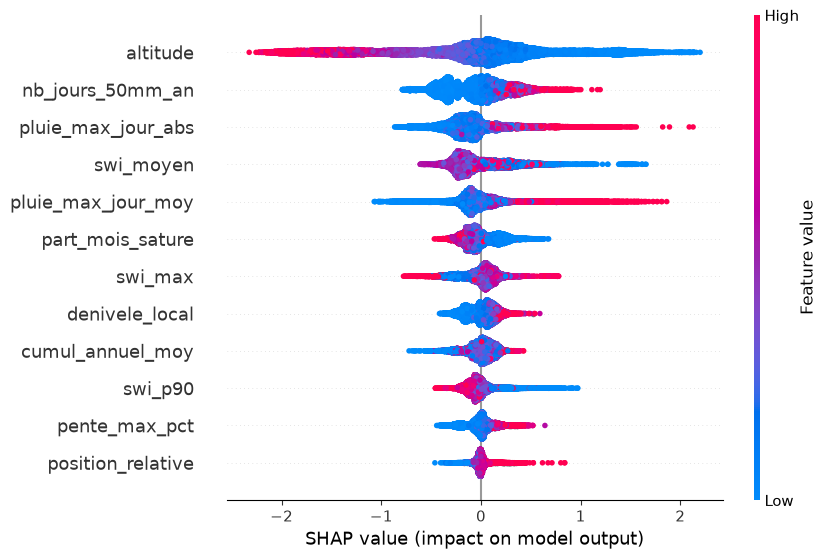

In [10]:
import shap

# Prédictions et valeurs SHAP hors échantillon : chaque commune est expliquée
# par le modèle qui ne l'a pas vue (le même que celui qui donne sa probabilité)
df["proba_risque"] = np.nan
shap_vals = np.zeros((len(df), len(features)))
shap_base = np.zeros(len(df))

for train, test in cv.split(X, y, groups):
    m = modele().fit(X.iloc[train], y.iloc[train])
    df.loc[df.index[test], "proba_risque"] = m.predict_proba(X.iloc[test])[:, 1]
    expl = shap.TreeExplainer(m)(X.iloc[test])
    shap_vals[test] = expl.values
    shap_base[test] = expl.base_values

# Contrôle : base + somme des SHAP (en log-odds) redonne bien la probabilité
reconstruite = 1 / (1 + np.exp(-(shap_base + shap_vals.sum(axis=1))))
print("Écart max proba / SHAP :", np.abs(reconstruite - df["proba_risque"]).max().round(6))

expl_oof = shap.Explanation(values=shap_vals, base_values=shap_base,
                            data=X.values, feature_names=features)
shap.plots.beeswarm(expl_oof, max_display=12)

In [11]:
# Sauvegarde pour l'app : prédictions, variables et contributions SHAP
for i, f in enumerate(features):
    df[f"shap_{f}"] = shap_vals[:, i]
df["shap_base"] = shap_base

cols = (["code_commune", "nom", "codeDepartement", "lon", "lat",
         "risque_fort", "nb_arretes_inond", "proba_risque"]
        + features + [f"shap_{f}" for f in features] + ["shap_base"])
df[cols].to_parquet("../data/predictions_v3.parquet", index=False)
print("Enregistré :", df[cols].shape)

Enregistré : (34746, 33)


## Résultat v3 (validation spatiale par département, 5 groupes)
- Données : 34 746 communes de métropole, cible corrigée, 12 variables (SWI + relief + pluies extrêmes)
- Probabilités calibrées : elles peuvent se lire comme des fréquences
- SHAP hors échantillon : les contributions d'une commune expliquent exactement la probabilité affichée dans l'app